# Ingeniería Económica
## Análisis de sensibilidad y simulación de Monte Carlo

**Cuaderno práctico · Python y Jupyter Notebook**

> **Pregunta central:** Un proyecto presenta VAN positivo y una TIR superior a la tasa de descuento. ¿Es suficiente para recomendar invertir?

Este cuaderno analiza **un mismo proyecto de inversión** desde tres perspectivas: su rentabilidad bajo supuestos conocidos, la sensibilidad ante cambios en sus variables y la distribución de resultados cuando algunos supuestos son inciertos.

**Al finalizar podrás:**

1. Calcular e interpretar VAN y TIR mediante `numpy-financial`.
2. Identificar variables críticas con análisis de sensibilidad y puntos de quiebre.
3. Simular resultados mediante el método de Monte Carlo.
4. Fundamentar una recomendación de inversión basada en indicadores y supuestos.

**Cómo utilizarlo:** ejecuta las celdas en orden, de arriba hacia abajo. Examina los resultados, modifica los supuestos propuestos y responde las actividades. Los gráficos se generan directamente a partir de los datos del modelo.


---
# 1. Introducción a NumPy Financial

## 1.1. ¿Para qué utilizar una librería financiera?

Los métodos de evaluación de proyectos ya conocidos pueden resolverse manualmente, con una planilla o mediante código. Una **librería** permite reutilizar funciones financieras probadas sin reprogramar cada fórmula.

- **`numpy-financial` (`npf`):** calcula indicadores como el valor actual neto, `npf.npv()`, y la tasa interna de retorno, `npf.irr()`.
- **`numpy` (`np`):** realiza cálculos numéricos y genera valores aleatorios para simulación.
- **`pandas` (`pd`):** organiza resultados en tablas.
- **`matplotlib`:** produce gráficos.

**Requisitos:** Python con `numpy`, `numpy-financial`, `pandas` y `matplotlib`. En Google Colab, puedes abrir el archivo desde **Archivo > Subir cuaderno**. Si falta `numpy-financial`, ejecuta `%pip install numpy-financial` en una celda independiente y luego vuelve a ejecutar el cuaderno desde el comienzo. No se requieren archivos de datos externos.

> **Convención importante:** el desembolso inicial se registra en el período 0 con signo negativo. `npf.npv(tasa, flujos)` **incluye el flujo del año 0**; no debe descontarse ni restarse dos veces.


In [1]:
import numpy as np
import numpy_financial as npf
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print('Librerias importadas correctamente.')


Librerias importadas correctamente.


## 1.2. Caso de estudio: inversión en equipamiento

Una empresa considera incorporar equipamiento para producir y comercializar un producto durante **tres años**. Se proyectan flujos **anuales, al cierre de cada año**, y una inversión inicial al comienzo del proyecto.

| Variable | Valor base | Unidad |
|:--|--:|:--|
| Inversión inicial | 70.000.000 | CLP |
| Precio unitario | 50.000 | CLP/unidad |
| Costo variable unitario | 20.000 | CLP/unidad |
| Unidades vendidas | 1.600 | unidades/año |
| Costos fijos operacionales | 12.000.000 | CLP/año |
| Tasa de descuento | 10 % | anual |
| Horizonte de evaluación | 3 | años |

**Alcance del modelo:** los supuestos permanecen constantes en los tres años; no hay impuestos, depreciación, capital de trabajo, valor residual, crecimiento ni inflación. Por lo tanto, los flujos son un ejemplo de **flujo neto operativo simplificado**, no una evaluación empresarial completa. La tasa es consistente con flujos expresados en pesos constantes bajo este supuesto.

El flujo neto anual se calcula como:

$$F = (P-C_v)Q-C_f$$

Donde $P$ es el precio unitario, $C_v$ el costo variable unitario, $Q$ la cantidad anual y $C_f$ el costo fijo anual.


In [2]:
# Supuestos del proyecto (cambia aqui un valor para experimentar).
BASE = {
    'inversion_inicial': 70_000_000,
    'precio_unitario': 50_000,
    'costo_variable_unitario': 20_000,
    'unidades_anuales': 1_600,
    'costo_fijo_anual': 12_000_000,
    'tasa_descuento': 0.10,
    'horizonte': 3,
}

def evaluar_proyecto(**modificaciones):
    """Calcula flujos, VAN y TIR de un proyecto con los supuestos indicados."""
    s = {**BASE, **modificaciones}
    flujo_anual = ((s['precio_unitario'] - s['costo_variable_unitario'])
                  * s['unidades_anuales'] - s['costo_fijo_anual'])
    flujos = np.r_[-s['inversion_inicial'],
                   np.repeat(flujo_anual, s['horizonte'])]
    return {
        'supuestos': s,
        'flujo_anual': flujo_anual,
        'flujos': flujos,
        'VAN': float(npf.npv(s['tasa_descuento'], flujos)),
        'TIR': float(npf.irr(flujos)),
    }

def clp(valor):
    """Formato resumido de valores monetarios en pesos."""
    monto = '${:,.0f}'.format(abs(valor)).replace(',', '.')
    return '-' + monto if valor < 0 else monto

base = evaluar_proyecto()
print('Flujo neto anual:', clp(base['flujo_anual']))
print('Flujos (años 0, 1, 2, 3):', [clp(f) for f in base['flujos']])
print('VAN:', clp(base['VAN']))
print('TIR: {:.2%}'.format(base['TIR']))
print('Tasa de descuento: {:.0%}'.format(BASE['tasa_descuento']))


Flujo neto anual: $36.000.000
Flujos (años 0, 1, 2, 3): ['-$70.000.000', '$36.000.000', '$36.000.000', '$36.000.000']
VAN: $19.526.672
TIR: 25.26%
Tasa de descuento: 10%


## 1.3. Diagrama de flujos de caja: la representación clásica de un proyecto

En Ingeniería Económica, el **diagrama de flujos de caja** es el punto de partida visual: ubica cada ingreso o egreso en el período correspondiente y recuerda que **no es indiferente recibir o pagar hoy que dentro de tres años**.

- Las **flechas hacia abajo** representan egresos, como la inversión inicial.
- Las **flechas hacia arriba** representan ingresos netos, como los flujos operacionales anuales.
- Cada flujo se sitúa en un **instante del tiempo**. En este caso, los flujos positivos ocurren al **final de cada año**.

La imagen se construye con los flujos que acabas de calcular, en millones de pesos. Si modificas los supuestos del caso, vuelve a ejecutar la celda del modelo y luego esta figura.


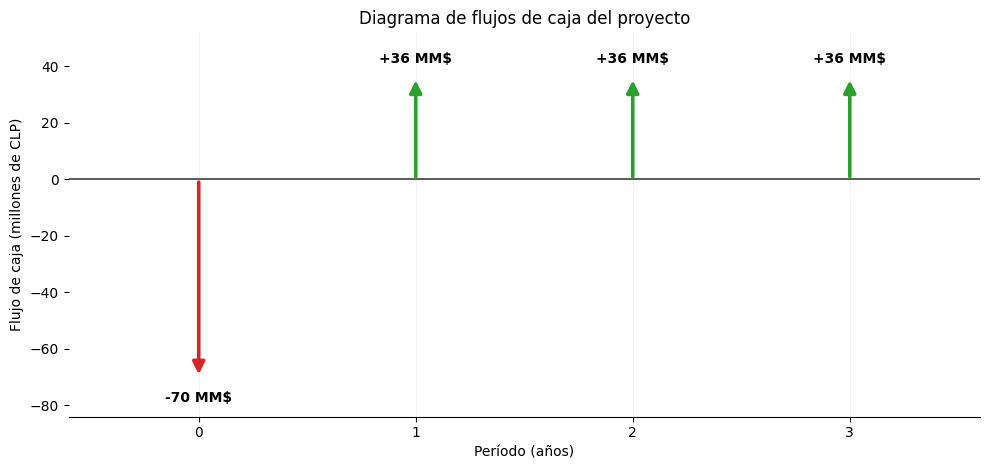

In [3]:
# Grafico clasico: diagrama de flujos de caja en el eje del tiempo.
flujos_mm = np.asarray(base['flujos'], dtype=float) / 1_000_000
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axhline(0, color='0.3', linewidth=1.3)
for periodo, flujo in enumerate(flujos_mm):
    ax.annotate('', xy=(periodo, flujo), xytext=(periodo, 0),
                arrowprops=dict(arrowstyle='-|>', lw=2.6,
                                color='tab:green' if flujo > 0 else 'tab:red',
                                mutation_scale=18))
    desplazamiento = 4 if flujo >= 0 else -5
    va = 'bottom' if flujo >= 0 else 'top'
    ax.text(periodo, flujo + desplazamiento, f'{flujo:+,.0f} MM$',
            ha='center', va=va, fontsize=10, fontweight='bold')
ax.set_xlim(-0.6, BASE['horizonte'] + 0.6)
ax.set_ylim(min(-84, flujos_mm.min() - 14), max(52, flujos_mm.max() + 14))
ax.set_xticks(np.arange(BASE['horizonte'] + 1))
ax.set_xlabel('Período (años)')
ax.set_ylabel('Flujo de caja (millones de CLP)')
ax.set_title('Diagrama de flujos de caja del proyecto')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.grid(axis='x', alpha=0.16)
plt.tight_layout()
plt.show()


## 1.4. Recordatorio: VAN y TIR

El **valor actual neto (VAN)** mide el valor que el proyecto agrega **después de remunerar el capital a la tasa exigida**:

$$VAN = \sum_{t=0}^{n}\frac{FC_t}{(1+r)^t}=-I_0+\sum_{t=1}^{n}\frac{FC_t}{(1+r)^t}$$

La **tasa interna de retorno (TIR)** es la tasa que hace que el VAN sea cero:

$$0=\sum_{t=0}^{n}\frac{FC_t}{(1+TIR)^t}$$

Para este proyecto independiente con flujos convencionales, se acepta financieramente si **VAN > 0** y, de manera equivalente para este caso, si **TIR > 10 %**. Una TIR alta no mide en pesos el valor creado: para priorizar proyectos mutuamente excluyentes o con flujos no convencionales, el VAN suele ser el criterio principal.

**Pregunta de análisis:** ¿Qué supuesto tendría que fallar para que el VAN fuese negativo?


## 1.5. Perfil del VAN: la conexión gráfica con la TIR

El **perfil del VAN** muestra cómo cambia el valor actual neto cuando la **tasa de descuento** varía y los flujos de caja se mantienen fijos.

- En la tasa exigida de **10 %**, el gráfico debe coincidir con el VAN calculado por `npf.npv`.
- El punto donde la curva cruza **VAN = 0** es la **TIR**, calculada por `npf.irr`.
- En este caso, con inversión inicial negativa seguida de flujos anuales positivos, la relación del VAN con la tasa es **decreciente** y la TIR es única.

**Pregunta de análisis:** si la tasa exigida aumenta y supera la TIR, ¿seguiría siendo conveniente el proyecto según el VAN?


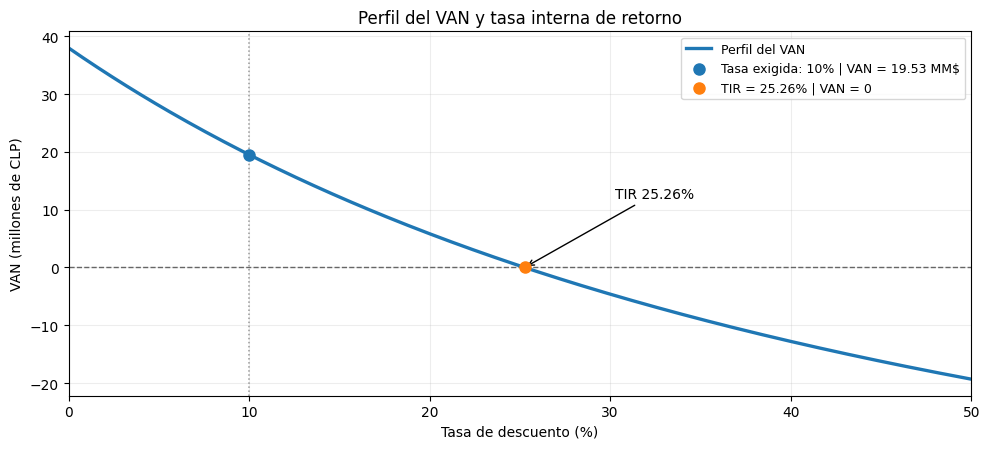

In [4]:
# Perfil del VAN: calculo del VAN para distintas tasas exigidas.
tasas = np.linspace(0, 0.50, 251)
perfil_van = np.array([npf.npv(t, base['flujos']) for t in tasas]) / 1e6
r_base = BASE['tasa_descuento']
tir_base = base['TIR']

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(tasas * 100, perfil_van, linewidth=2.4, label='Perfil del VAN')
ax.axhline(0, color='0.4', linestyle='--', linewidth=1)
ax.axvline(r_base * 100, color='0.6', linestyle=':', linewidth=1.1)
ax.scatter([r_base * 100], [base['VAN']/1e6], s=64, zorder=5,
           label=f'Tasa exigida: {r_base:.0%} | VAN = {base["VAN"]/1e6:.2f} MM$')
ax.scatter([tir_base * 100], [0], s=64, zorder=6,
           label=f'TIR = {tir_base:.2%} | VAN = 0')
ax.annotate(f'TIR {tir_base:.2%}', xy=(tir_base*100, 0),
            xytext=(tir_base*100 + 5, 12),
            arrowprops=dict(arrowstyle='->', lw=1), fontsize=10)
ax.set_xlim(0, 50)
ax.set_xlabel('Tasa de descuento (%)')
ax.set_ylabel('VAN (millones de CLP)')
ax.set_title('Perfil del VAN y tasa interna de retorno')
ax.grid(alpha=0.22)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()


---
# 2. Riesgo, incertidumbre y análisis de sensibilidad

## 2.1. Del resultado único al análisis de supuestos

El VAN y la TIR anteriores provienen de **un conjunto específico de proyecciones**. No son garantías: el precio, las ventas y los costos futuros pueden diferir de lo esperado.

- **Riesgo:** situación en que pueden plantearse resultados alternativos y estimarse o suponerse probabilidades para ellos.
- **Incertidumbre:** desconocimiento de valores futuros y, en su sentido más estricto, ausencia de probabilidades confiables.
- **Análisis de sensibilidad:** estudio de cómo cambia un resultado (VAN o TIR) cuando cambian los supuestos del modelo. Por sí solo **no asigna probabilidades**.

Las fronteras entre riesgo e incertidumbre pueden variar entre autores. En este cuaderno, Monte Carlo será una **ilustración probabilística condicionada a supuestos**, no una estimación estadística validada del riesgo real.

## 2.2. Sensibilidad univariable (ceteris paribus)

La técnica consiste en modificar **una variable a la vez** y mantener fijas las demás. Responde preguntas como: ¿Cuánto cae el VAN si el precio disminuye 10 %?

**Modelo de referencia:** si los demás supuestos no cambian, el efecto de variar el precio es lineal sobre el flujo anual: $\Delta F = Q \cdot \Delta P$. Como el VAN descuenta flujos futuros, cada modificación del precio genera una variación sistemática del VAN. El gráfico siguiente permite observar ese efecto y, mediante `npf.irr()`, su impacto sobre la TIR.

**Advertencia:** variar el precio sin modificar la demanda es una simplificación. En mercados reales puede existir una relación entre ambos.


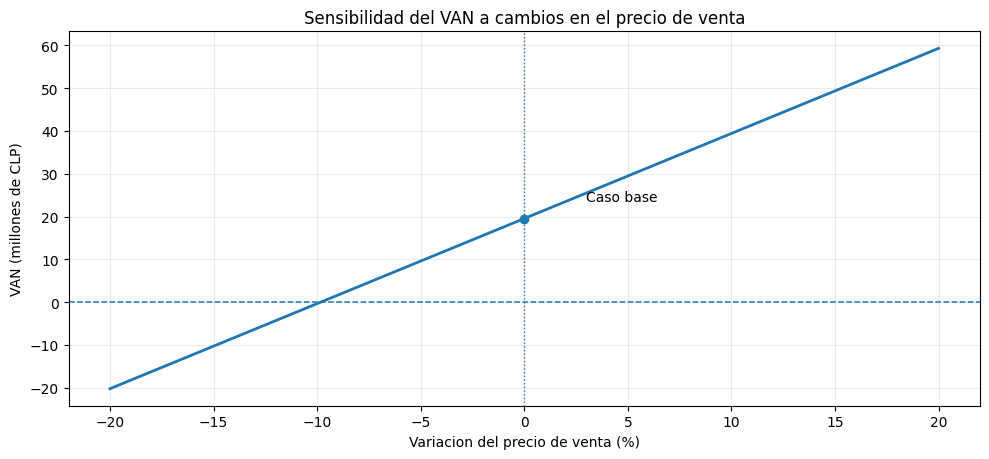

Precio -10%: VAN -$368.144 | TIR 9.70%
Precio +0%: VAN $19.526.672 | TIR 25.26%
Precio +10%: VAN $39.421.488 | TIR 39.90%


In [5]:
# Sensibilidad del VAN y la TIR al precio de venta (-20 % a +20 %).
variaciones = np.linspace(-0.20, 0.20, 81)
vanes_precio = np.array([
    evaluar_proyecto(precio_unitario=BASE['precio_unitario'] * (1 + v))['VAN']
    for v in variaciones
])
tires_precio = np.array([
    evaluar_proyecto(precio_unitario=BASE['precio_unitario'] * (1 + v))['TIR']
    for v in variaciones
])

fig, ax = plt.subplots(figsize=(10, 4.7))
ax.plot(variaciones * 100, vanes_precio / 1e6, linewidth=2)
ax.axhline(0, linestyle='--', linewidth=1.1)
ax.axvline(0, linestyle=':', linewidth=1)
ax.scatter([0], [base['VAN']/1e6], zorder=5)
ax.annotate('Caso base', (0, base['VAN']/1e6), xytext=(3, base['VAN']/1e6 + 4))
ax.set(title='Sensibilidad del VAN a cambios en el precio de venta',
       xlabel='Variacion del precio de venta (%)', ylabel='VAN (millones de CLP)')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

for v in [-0.10, 0, 0.10]:
    r = evaluar_proyecto(precio_unitario=BASE['precio_unitario'] * (1 + v))
    print('Precio {:+.0%}: VAN {} | TIR {:.2%}'.format(v, clp(r['VAN']), r['TIR']))


> **Actividad 1.** Identifica el valor aproximado de caída del precio a partir del cual el proyecto deja de crear valor. Luego compara el VAN con una disminución de 10 % y un aumento de 10 %. ¿Es simétrico su efecto en este modelo? ¿Por qué?

## 2.3. Identificación de variables críticas: gráfico de tornado

Un **gráfico de tornado** permite comparar cuánto varía el VAN cuando se modifica individualmente cada entrada dentro de un rango elegido. Cuanto mayor es el intervalo del VAN, más sensible es el proyecto a esa variable **dentro del rango estudiado**.

En el ejercicio cambiaremos **±10 %** el precio, las unidades, el costo variable, los costos fijos y la inversión. El rango es ilustrativo y no representa necesariamente variaciones igual de probables o realistas.


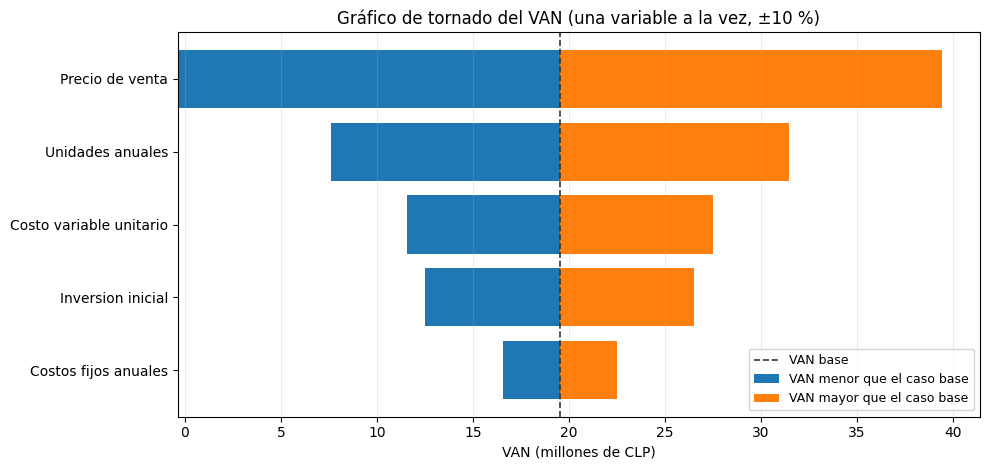

,Variable,VAN minimo (MM$),VAN maximo (MM$),Amplitud del VAN (MM$)
0,Precio de venta,-0.37,39.42,39.79
1,Unidades anuales,7.59,31.46,23.87
2,Costo variable unitario,11.57,27.48,15.92
4,Inversion inicial,12.53,26.53,14.00
3,Costos fijos anuales,16.54,22.51,5.97


In [6]:
# Gráfico de tornado: misma variación porcentual, una variable a la vez.
variables = {
    'Precio de venta': 'precio_unitario',
    'Unidades anuales': 'unidades_anuales',
    'Costo variable unitario': 'costo_variable_unitario',
    'Costos fijos anuales': 'costo_fijo_anual',
    'Inversion inicial': 'inversion_inicial',
}
registros_tornado = []
for etiqueta, clave in variables.items():
    valor = BASE[clave]
    van_menos = evaluar_proyecto(**{clave: valor * 0.90})['VAN'] / 1e6
    van_mas = evaluar_proyecto(**{clave: valor * 1.10})['VAN'] / 1e6
    registros_tornado.append({
        'Variable': etiqueta,
        'VAN minimo (MM$)': min(van_menos, van_mas),
        'VAN maximo (MM$)': max(van_menos, van_mas),
        'Amplitud del VAN (MM$)': abs(van_mas - van_menos),
    })
tornado = pd.DataFrame(registros_tornado).sort_values('Amplitud del VAN (MM$)')
van_base_mm = base['VAN'] / 1e6
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(tornado['Variable'], van_base_mm - tornado['VAN minimo (MM$)'],
        left=tornado['VAN minimo (MM$)'], label='VAN menor que el caso base')
ax.barh(tornado['Variable'], tornado['VAN maximo (MM$)'] - van_base_mm,
        left=van_base_mm, label='VAN mayor que el caso base')
ax.axvline(van_base_mm, color='0.2', linestyle='--', linewidth=1.2,
           label='VAN base')
ax.set(title='Gráfico de tornado del VAN (una variable a la vez, ±10 %)',
       xlabel='VAN (millones de CLP)')
ax.grid(axis='x', alpha=0.25)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()
display(tornado.sort_values('Amplitud del VAN (MM$)', ascending=False).round(2))


> **Actividad 2.** Ordena las tres variables con mayor amplitud de VAN. ¿La variable más sensible es necesariamente la que genera mayor **riesgo**? Justifica tu respuesta distinguiendo el impacto de una variación de su probabilidad de ocurrencia.

## 2.4. Valor crítico o punto de quiebre

Un **valor crítico** es el valor de una variable que hace que la decisión cambie. Para el precio, definiremos como criterio el punto donde **VAN = 0**: el proyecto recupera la inversión y exactamente remunera la tasa exigida.

Si el flujo anual es constante, el factor de anualidad a tasa $r$ y horizonte $n$ es:

$$A(r,n)=\sum_{t=1}^{n}\frac{1}{(1+r)^t}$$

Como $VAN=-I_0+[(P-C_v)Q-C_f]A(r,n)$, al despejar el precio que hace $VAN=0$ se obtiene:

$$\boxed{P_{\mathrm{crítico}}=C_v+\frac{C_f+I_0/A(r,n)}{Q}}$$

**No confundir** este precio crítico financiero con el punto de equilibrio operacional, que no considera el costo de oportunidad del capital ni la recuperación de la inversión inicial.


In [7]:
r = BASE['tasa_descuento']
n = BASE['horizonte']
factor_anualidad = sum(1 / (1 + r)**t for t in range(1, n + 1))

precio_critico = (
    BASE['costo_variable_unitario'] +
    (BASE['costo_fijo_anual'] + BASE['inversion_inicial'] / factor_anualidad)
    / BASE['unidades_anuales']
)
precio_equilibrio_operativo = (
    BASE['costo_variable_unitario'] +
    BASE['costo_fijo_anual'] / BASE['unidades_anuales']
)
caida_critica = (1 - precio_critico / BASE['precio_unitario']) * 100
van_verificacion = evaluar_proyecto(precio_unitario=precio_critico)['VAN']

print('Precio critico financiero:', clp(precio_critico))
print('Caida que agota el VAN base: {:.2f}%'.format(caida_critica))
print('VAN al precio critico:', clp(van_verificacion))
print('Precio de equilibrio operacional:', clp(precio_equilibrio_operativo))


Precio critico financiero: $45.093
Caida que agota el VAN base: 9.81%
VAN al precio critico: -$0
Precio de equilibrio operacional: $27.500


> **Actividad 3.** Si el precio unitario esperado disminuyera **12 %**, ¿mantendrías la recomendación? Justifica con el precio crítico y luego verifica ejecutando `evaluar_proyecto(precio_unitario=44_000)`.

## 2.5. Análisis de escenarios

A diferencia de la sensibilidad univariable, un **escenario** modifica **varias variables en conjunto** para representar una situación coherente: optimista, base o pesimista. No equivale todavía a Monte Carlo; estos tres casos **no tienen probabilidades asignadas**.

Estudiaremos cambios simultáneos del precio, el volumen de ventas, los costos y, en el escenario pesimista, la inversión. Son hipótesis ilustrativas, no pronósticos de mercado.

| Variable | Optimista | Base | Pesimista |
|:--|--:|--:|--:|
| Precio unitario | +5 % | Sin cambio | −8 % |
| Unidades anuales | +10 % | Sin cambio | −15 % |
| Costo variable unitario | −5 % | Sin cambio | +10 % |
| Costos fijos anuales | −5 % | Sin cambio | +10 % |
| Inversión inicial | Sin cambio | Sin cambio | +5 % |

**Interpretación:** los escenarios representan **conjuntos coherentes de hipótesis**, no tres resultados igualmente probables. El VAN de cada escenario se obtiene recalculando el flujo con todos los supuestos correspondientes.


In [8]:
# Cada registro representa cambios simultaneos respecto del caso base.
escenarios = {
    'Optimista': {
        'precio_unitario': 1.05, 'unidades_anuales': 1.10,
        'costo_variable_unitario': 0.95, 'costo_fijo_anual': 0.95,
        'inversion_inicial': 1.00,
    },
    'Base': {
        'precio_unitario': 1.00, 'unidades_anuales': 1.00,
        'costo_variable_unitario': 1.00, 'costo_fijo_anual': 1.00,
        'inversion_inicial': 1.00,
    },
    'Pesimista': {
        'precio_unitario': 0.92, 'unidades_anuales': 0.85,
        'costo_variable_unitario': 1.10, 'costo_fijo_anual': 1.10,
        'inversion_inicial': 1.05,
    },
}
filas = []
for nombre, factores in escenarios.items():
    cambios = {campo: BASE[campo] * multip for campo, multip in factores.items()}
    resultado = evaluar_proyecto(**cambios)
    filas.append({
        'Escenario': nombre,
        'VAN (MM$)': round(resultado['VAN'] / 1e6, 2),
        'TIR (%)': round(resultado['TIR'] * 100, 2),
        'VAN > 0': 'Si' if resultado['VAN'] > 0 else 'No'
    })
tabla_escenarios = pd.DataFrame(filas)
display(tabla_escenarios)


,Escenario,VAN (MM$),TIR (%),VAN > 0
0,Optimista,48.27,46.20,Si
1,Base,19.53,25.26,Si
2,Pesimista,-25.16,-10.73,No


> **Ideas clave.** La sensibilidad muestra **impactos ante cambios supuestos**; el tornado destaca variables influyentes; los valores críticos indican límites de la decisión; y los escenarios muestran **combinaciones concretas**. Ninguno de estos análisis, por sí solo, estima la probabilidad de perder valor.


---
# 3. Simulación de Monte Carlo

## 3.1. ¿Qué aporta Monte Carlo?

La **simulación de Monte Carlo** utiliza un modelo de resultados y distribuciones probabilísticas para generar muchos conjuntos de supuestos posibles. Cada conjunto produce un VAN y una TIR; sus resultados permiten estudiar una **distribución de resultados**, no solo un valor aislado.

**Enfoque de trabajo:** ejecuta las simulaciones y analiza qué variables se generan aleatoriamente, cómo se calcula el VAN y cómo se interpretan los resultados.

**Procedimiento conceptual:**

1. Escoger variables inciertas y sus distribuciones.
2. Generar aleatoriamente un conjunto de valores para cada simulación.
3. Recalcular los flujos, el VAN y la TIR.
4. Repetir miles de veces y resumir la distribución obtenida.

Emplearemos la **distribución triangular** porque permite especificar un mínimo, un valor más probable (moda) y un máximo. Es intuitiva para una demostración, pero no debe utilizarse en decisiones reales sin fundamentar sus parámetros y contrastarlos con evidencia.

| Variable simulada | Mínimo | Moda | Máximo |
|:--|--:|--:|--:|
| Precio de venta (CLP/u) | 45.000 | 50.000 | 55.000 |
| Ventas anuales (unidades) | 1.300 | 1.600 | 1.900 |
| Costo variable unitario (CLP/u) | 18.000 | 20.000 | 24.000 |

**Supuestos explícitos de la simulación:** (i) las tres variables se modelan como **independientes**, (ii) en cada simulación los valores sorteados se mantienen constantes durante los tres años y (iii) inversión, costos fijos, tasa de descuento y horizonte permanecen fijos. Estos supuestos facilitan la comprensión, pero pueden ser poco realistas: por ejemplo, precio y demanda suelen estar relacionados.

> **Importante:** las probabilidades que calcularemos son **condicionales al modelo y a las distribuciones elegidas**, no probabilidades observadas ni garantizadas para una empresa real.


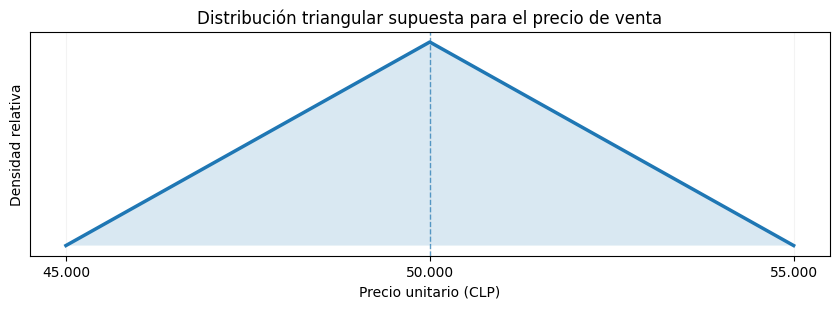

In [9]:
# La distribucion triangular del precio: minimo, moda y maximo.
precio_min, precio_moda, precio_max = 45_000, 50_000, 55_000
valores = np.array([precio_min, precio_moda, precio_max])
alturas = np.array([0, 2 / (precio_max - precio_min), 0])
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.plot(valores, alturas, lw=2.5)
ax.fill_between(valores, alturas, alpha=0.17)
ax.axvline(precio_moda, linestyle='--', linewidth=1, alpha=0.7)
ax.set(title='Distribución triangular supuesta para el precio de venta',
       xlabel='Precio unitario (CLP)', ylabel='Densidad relativa')
ax.set_xticks([precio_min, precio_moda, precio_max], ['45.000', '50.000', '55.000'])
ax.set_yticks([])
ax.grid(axis='x', alpha=0.15)
plt.tight_layout()
plt.show()


In [10]:
# Paso 1: crear 5.000 conjuntos de supuestos aleatorios reproducibles.
SEMILLA = 2026       # Cambia la semilla para explorar otra muestra.
N = 5_000            # Numero de simulaciones.
rng = np.random.default_rng(SEMILLA)

precios_mc = rng.triangular(45_000, 50_000, 55_000, N)
unidades_mc = np.rint(rng.triangular(1_300, 1_600, 1_900, N)).astype(int)
costos_mc = rng.triangular(18_000, 20_000, 24_000, N)

# Paso 2: flujos netos anuales en cada uno de los 5.000 escenarios.
flujos_anuales_mc = (
    (precios_mc - costos_mc) * unidades_mc - BASE['costo_fijo_anual']
)

# Paso 3: evaluar cada escenario usando numpy-financial.
inversion = BASE['inversion_inicial']
tasa = BASE['tasa_descuento']
horizonte = BASE['horizonte']
vanes_mc = np.array([
    npf.npv(tasa, [-inversion] + [float(f)] * horizonte)
    for f in flujos_anuales_mc
])
tires_mc = np.array([
    npf.irr([-inversion] + [float(f)] * horizonte)
    for f in flujos_anuales_mc
])

simulaciones = pd.DataFrame({
    'Precio (CLP)': precios_mc,
    'Unidades anuales': unidades_mc,
    'Costo variable (CLP/u)': costos_mc,
    'VAN (CLP)': vanes_mc,
    'TIR (%)': tires_mc * 100,
})
print(f'Simulaciones realizadas: {len(simulaciones):,}'.replace(',', '.'))
display(simulaciones.head(6).round(2))


Simulaciones realizadas: 5.000


,Precio (CLP),Unidades anuales,Costo variable (CLP/u),VAN (CLP),TIR (%)
0,47991.11,1745,22635.30,10190764.43,18.10
1,50756.85,1674,21832.24,20570634.65,26.05
2,49833.57,1446,20588.42,5322975.11,14.27
3,49304.07,1684,21321.10,17346503.60,23.61
4,49212.58,1586,19157.49,18699487.52,24.64
5,51763.63,1708,21871.46,27126056.58,30.94


## 3.2. Interpretar resultados probabilísticos

De cada distribución observaremos:

- **Media:** promedio de los resultados simulados. Puede diferir del resultado del caso base por asimetría o por relaciones no lineales.
- **Mediana (percentil 50):** la mitad de las simulaciones está por debajo y la otra mitad por encima.
- **Percentiles 5 y 95:** delimitan la zona donde cae el 90 % central **de los resultados simulados**; no son un intervalo de confianza del parámetro desconocido.
- **Probabilidad estimada de VAN negativo:** fracción de simulaciones con $VAN<0$. Es una medida de riesgo de destruir valor según este modelo.
- **Probabilidad estimada de TIR inferior a la tasa exigida:** fracción con $TIR<10\%$; para el modelo de flujos convencionales de este caso, la clasificación coincide con $VAN<0$.

Un **histograma** representa cuántas simulaciones se acumulan en cada intervalo. Su forma depende de las distribuciones iniciales, sus rangos y las relaciones entre variables.


In [11]:
# Estadisticos de los VAN y TIR simulados.
prob_van_negativo = np.mean(vanes_mc < 0)
prob_tir_insuficiente = np.mean(tires_mc < BASE['tasa_descuento'])
resumen_mc = pd.DataFrame({
    'Indicador': ['VAN (MM$)', 'TIR (%)'],
    'Caso base': [base['VAN']/1e6, 100*base['TIR']],
    'Media simulada': [np.mean(vanes_mc)/1e6, np.mean(tires_mc)*100],
    'Mediana': [np.median(vanes_mc)/1e6, np.median(tires_mc)*100],
    'Percentil 5': [np.percentile(vanes_mc, 5)/1e6,
                    np.percentile(tires_mc, 5)*100],
    'Percentil 95': [np.percentile(vanes_mc, 95)/1e6,
                     np.percentile(tires_mc, 95)*100],
})
display(resumen_mc.round(2))
print('P(VAN < 0) estimada: {:.1%}'.format(prob_van_negativo))
print('P(TIR < 10 %) estimada: {:.1%}'.format(prob_tir_insuficiente))


,Indicador,Caso base,Media simulada,Mediana,Percentil 5,Percentil 95
0,VAN (MM$),19.53,17.27,17.09,-3.40,39.36
1,TIR (%),25.26,23.35,23.41,7.22,39.86


P(VAN < 0) estimada: 8.8%
P(TIR < 10 %) estimada: 8.8%


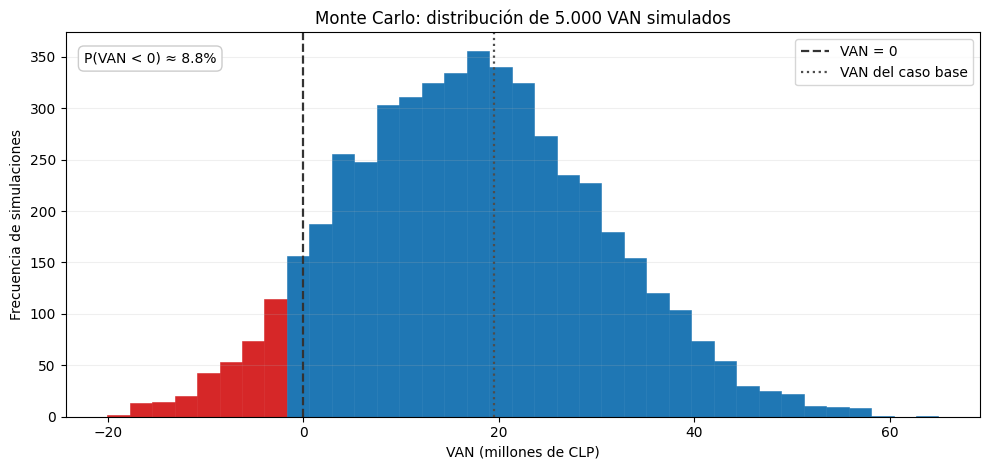

In [12]:
# Histograma de Monte Carlo: casos que crean y destruyen valor.
fig, ax = plt.subplots(figsize=(10, 4.8))
lim_min = min(np.min(vanes_mc/1e6), 0)
lim_max = max(np.max(vanes_mc/1e6), 0)
bordes = np.linspace(lim_min, lim_max, 38)
conteos, bordes, barras = ax.hist(vanes_mc / 1e6, bins=bordes,
                                  edgecolor='white', linewidth=0.4)
for izquierda, derecha, barra in zip(bordes[:-1], bordes[1:], barras):
    if derecha <= 0:
        barra.set_color('tab:red')
    else:
        barra.set_color('tab:blue')
ax.axvline(0, color='0.2', linestyle='--', linewidth=1.6, label='VAN = 0')
ax.axvline(base['VAN']/1e6, color='0.3', linestyle=':', linewidth=1.6,
           label='VAN del caso base')
ax.text(0.02, 0.95, 'P(VAN < 0) ≈ {:.1%}'.format(prob_van_negativo),
        transform=ax.transAxes, ha='left', va='top', fontsize=10,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='0.8'))
ax.set(title='Monte Carlo: distribución de 5.000 VAN simulados',
       xlabel='VAN (millones de CLP)', ylabel='Frecuencia de simulaciones')
ax.legend()
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()


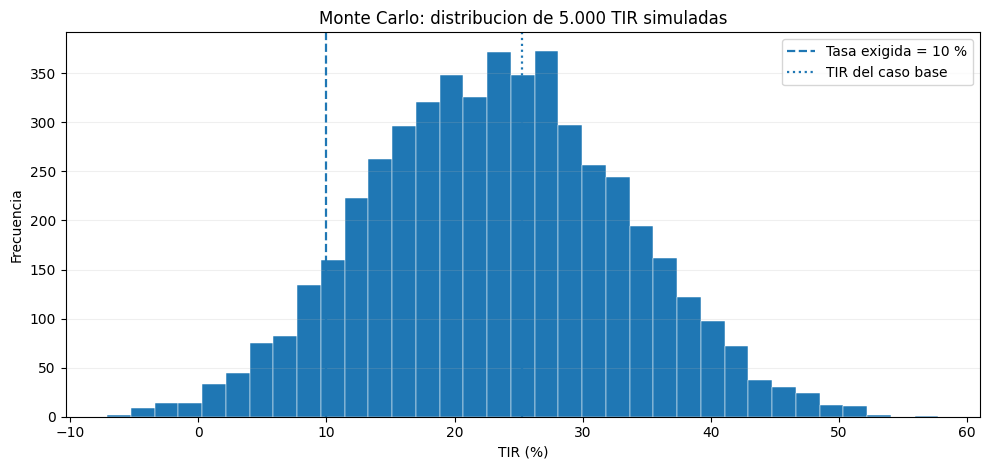

In [13]:
# Distribucion de la TIR simulada.
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(tires_mc * 100, bins=35, edgecolor='white', linewidth=0.35)
ax.axvline(BASE['tasa_descuento'] * 100, linestyle='--', linewidth=1.6,
           label='Tasa exigida = 10 %')
ax.axvline(base['TIR'] * 100, linestyle=':', linewidth=1.6, label='TIR del caso base')
ax.set(title='Monte Carlo: distribucion de 5.000 TIR simuladas',
       xlabel='TIR (%)', ylabel='Frecuencia')
ax.legend()
ax.grid(axis='y', alpha=0.20)
plt.tight_layout()
plt.show()


> **Actividad 4.** Con los resultados visibles: (a) ¿Qué fracción de escenarios destruye valor? (b) ¿El VAN base es igual al VAN promedio simulado? (c) ¿Por qué una distribución con VAN medio positivo todavía puede presentar resultados negativos?

### Explora los resultados

Vuelve a ejecutar **desde la celda que genera las simulaciones**, pero cambia el precio mínimo de `45_000` a `40_000`. ¿Aumenta o disminuye la probabilidad de VAN negativo? ¿En qué medida depende tu conclusión de ese supuesto?

**Observación:** una semilla fija permite reproducir los mismos resultados; cambiarla produce otra muestra. Aumentar el número de simulaciones suele estabilizar la frecuencia estimada, pero **no corrige una distribución equivocada ni datos deficientes**.


---
# 4. Interpretación de resultados y toma de decisiones

## 4.1. Síntesis de resultados del proyecto

La tabla resume **los resultados efectivamente calculados** a partir de los supuestos actuales del Notebook. Si se modifican los escenarios o las distribuciones probabilísticas, es necesario ejecutar nuevamente desde las celdas correspondientes antes de tomar una decisión.


In [14]:
# Resumen de indicadores del proyecto.
variable_mas_sensible = tornado.sort_values('Amplitud del VAN (MM$)', ascending=False).iloc[0]['Variable']
indicadores = pd.DataFrame([
    ['VAN del caso base', clp(base['VAN']), 'Resultado deterministico positivo'],
    ['TIR del caso base', f"{base['TIR']:.2%}", 'Comparar con la tasa exigida del 10 %'],
    ['Variable mas sensible', variable_mas_sensible, 'Dentro del rango de +/-10 %'],
    ['Precio critico financiero', clp(precio_critico), f'Caida admisible del precio: {caida_critica:.2f} %'],
    ['VAN medio simulado', clp(float(np.mean(vanes_mc))), 'Condicionado a distribuciones elegidas'],
    ['P(VAN negativo) estimada', f'{prob_van_negativo:.1%}', f'{int(np.sum(vanes_mc < 0))} de {N} simulaciones'],
], columns=['Indicador', 'Resultado', 'Lectura economica'])
display(indicadores)


,Indicador,Resultado,Lectura economica
0,VAN del caso base,$19.526.672,Resultado deterministico positivo
1,TIR del caso base,25.26%,Comparar con la tasa exigida del 10 %
2,Variable mas sensible,Precio de venta,Dentro del rango de +/-10 %
3,Precio critico financiero,$45.093,Caida admisible del precio: 9.81 %
4,VAN medio simulado,$17.272.076,Condicionado a distribuciones elegidas
5,P(VAN negativo) estimada,8.8%,440 de 5000 simulaciones


## 4.2. Desafío final: ¿recomendarías invertir?

Una empresa evalúa invertir **$70 millones** en equipamiento. El proyecto tiene rentabilidad positiva bajo el escenario base, pero depende de supuestos que podrían variar.

**Elabora una recomendación y justifícala con los resultados del cuaderno:**

- **Invertir:** indicar por qué la rentabilidad y los riesgos son aceptables.
- **No invertir:** explicar qué evidencia justifica renunciar al VAN positivo del caso base.
- **Invertir sujeto a condiciones:** identificar las condiciones necesarias (por ejemplo, asegurar un precio mínimo, validar la demanda o reducir costos).

La argumentación debe usar **tres evidencias**: (i) VAN y TIR del caso base; (ii) variable más sensible y precio crítico; (iii) distribución probabilística y proporción estimada de VAN negativos.

**No hay una única respuesta válida:** la decisión depende de las restricciones y la tolerancia al riesgo del inversionista. Explicita los supuestos, la evidencia y las limitaciones de tu recomendación.

## 4.3. Síntesis de herramientas

| Herramienta | Pregunta a la que responde | ¿Entrega probabilidades? |
|:--|:--|:--:|
| VAN y TIR | ¿Es rentable bajo estos supuestos? | No |
| Sensibilidad univariable | ¿Qué pasa si cambia una variable? | No |
| Tornado | ¿Cuáles variables influyen más dentro de los rangos elegidos? | No |
| Precio crítico | ¿En qué valor cambia la decisión? | No |
| Escenarios | ¿Qué pasa cuando varias variables cambian simultáneamente? | No, salvo asignación adicional |
| Monte Carlo | ¿Qué distribución de resultados surge de los supuestos probabilísticos? | Sí, condicional a esos supuestos |

> **Conclusión:** una evaluación económica no debe limitarse a determinar si el proyecto es rentable en un único escenario. También debe analizar **qué tan robusta es su rentabilidad** frente a cambios en los supuestos y **qué incertidumbres requieren ser gestionadas**.


---
# Material complementario

## Claves para interpretar los gráficos

| Gráfico | Qué observar | Qué **no** permite concluir |
|:--|:--|:--|
| Flujos de caja | Signo, monto y año de cada flujo | Rentabilidad sin aplicar una tasa |
| Perfil del VAN | Tasa exigida, intersección con VAN = 0 (TIR) | Una probabilidad de éxito |
| Tornado | Amplitud del VAN frente a rangos definidos | Que la variable más sensible sea necesariamente la más incierta |
| Histograma del VAN | Centro, dispersión y masa con VAN < 0 | Riesgo real si los supuestos probabilísticos no están validados |

## A. Supuestos y límites metodológicos

1. **Tasa de descuento:** debe reflejar el costo de oportunidad y el riesgo pertinente para los flujos que se analizan. No debe mezclarse una tasa nominal con flujos reales o períodos diferentes.
2. **TIR y flujos no convencionales:** múltiples cambios de signo en la serie de flujos pueden generar múltiples TIR o tornar ambigua su interpretación. No debe preferirse mecánicamente una TIR mayor entre proyectos de distinta escala.
3. **Correlación de variables:** en decisiones reales, precio, demanda, costos e inversión pueden no ser independientes. Ignorar sus dependencias puede subestimar o sobrestimar la exposición.
4. **Distribuciones:** una triangular puede construirse con juicios de expertos cuando faltan datos, pero sus parámetros deben documentarse y validarse. Si existe información histórica, conviene contrastar modelos alternativos.
5. **Horizonte y temporalidad:** este ejemplo supone valores anuales constantes. En evaluaciones reales se deberían considerar la estacionalidad, la variación anual, impuestos, recuperación de capital de trabajo, inversiones de reposición y valores terminales cuando correspondan.
6. **Rangos de sensibilidad:** comparar variaciones del mismo porcentaje permite una demostración sencilla, pero no significa que sean igualmente plausibles. Para una decisión real, deben provenir de evidencia o escenarios fundamentados.

## B. Lecturas y documentación de referencia

- NumPy Financial. [Documentación de funciones financieras](https://numpy.org/numpy-financial/latest/). Incluye `npv` e `irr`.
- NumPy Financial. [Referencia de la función `irr`](https://numpy.org/numpy-financial/latest/_api_stubs/numpy_financial.irr.html).
- NumPy. [Distribución triangular con `Generator.triangular`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.triangular.html).
- National Institute of Standards and Technology (NIST). [Monte Carlo Tool](https://www.nist.gov/services-resources/software/monte-carlo-tool): simulación de sensibilidad probabilística y uso de distribuciones.
- Blank, L. y Tarquin, A. *Engineering Economy*. Referencia de evaluación económica de proyectos.
- Park, C. S. *Contemporary Engineering Economics*. Referencia de fundamentos y evaluación de decisiones de inversión.

**Alcance:** los datos y las distribuciones son ilustrativos; no representan proyecciones validadas de una empresa real.


## C. Extensión opcional: sensibilidad simultánea precio × cantidad

Además de escenarios puntuales, podemos explorar una **matriz de dos variables** sin asignar probabilidades. Es útil para identificar combinaciones de precio y cantidad que vuelven negativo el VAN.


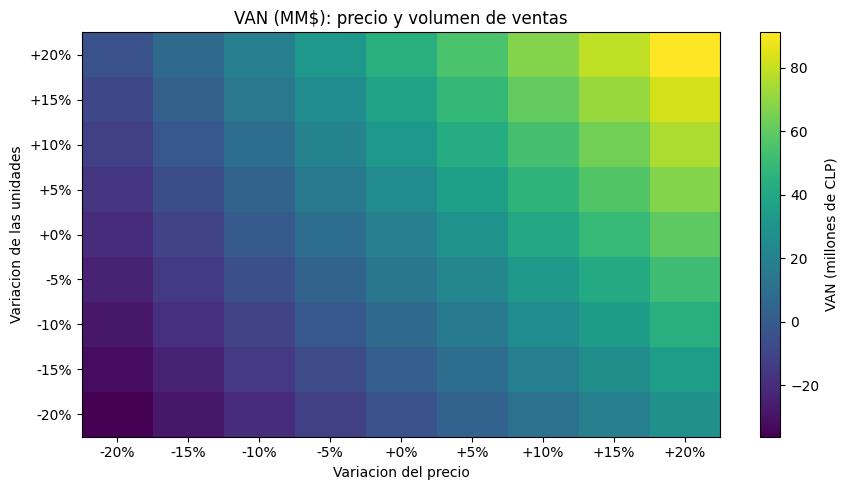

In [15]:
# Extension opcional: mapa de VAN para combinaciones de precio y cantidad.
variacion_precio = np.linspace(-0.20, 0.20, 9)
variacion_cantidad = np.linspace(-0.20, 0.20, 9)
matriz_van = np.array([
    [evaluar_proyecto(
        precio_unitario=BASE['precio_unitario'] * (1 + pv),
        unidades_anuales=BASE['unidades_anuales'] * (1 + qv)
      )['VAN'] / 1e6 for pv in variacion_precio]
    for qv in variacion_cantidad
])

fig, ax = plt.subplots(figsize=(9, 5))
img = ax.imshow(matriz_van, origin='lower', aspect='auto')
ax.set_xticks(range(len(variacion_precio)),
              [f'{p:+.0%}' for p in variacion_precio])
ax.set_yticks(range(len(variacion_cantidad)),
              [f'{q:+.0%}' for q in variacion_cantidad])
ax.set(title='VAN (MM$): precio y volumen de ventas',
       xlabel='Variacion del precio', ylabel='Variacion de las unidades')
fig.colorbar(img, ax=ax, label='VAN (millones de CLP)')
plt.tight_layout()
plt.show()
